
# Desktriage category and priority classifier

Shared BiLSTM with two heads. One head predicts `category`, the other predicts operational `priority`. The input is `query_text` together with `escalation_reason`.

The fitted model, label order, and `evaluation_summary.json` are written to `models/`. The worker loads that export. Training is logged to a new Comet project for Desktriage.

The dataset is synthetic. The metrics describe this dataset.

The phrase rules in `config/priority_policy.yaml` are still what the worker runs today. This notebook trains a priority head beside them and scores both on the held-out users.



## Why this model

Category and priority are two decisions read from the same short query. A shared encoder with a head for each decision trains both without a second network. Caruana (1997) describes that shared representation as a regulariser when the tasks use the same input.

The encoder is a two layer bidirectional LSTM: an embedding, spatial dropout, a bidirectional LSTM that returns the sequence, a second bidirectional LSTM, dropout, then a small dense head per task. Bidirectional LSTMs read the utterance in both directions, which is the right inductive bias for a one or two sentence query (Graves and Schmidhuber, 2005).

Inductive bias is that the order of the words appearing in the query matters.

Three recent comparisons support this model for a local ticket classifier:

- Zangari et al. (2023) include a bidirectional recurrent network trained from scratch (DeepTriage) as a ticket classifier. It is a recognised approach for this task.
- The 2024 *Expert Systems with Applications* benchmark ranked a BiLSTM first across 20 datasets and 11 model families. On multi-class tasks it was the top-ranked model.
- Roszczyk et al. (2026) compared Naive Bayes, a BiLSTM, and BERT on about 12,000 IT tickets. The BiLSTM reached about 98.6% accuracy and BERT about 99.2%. They kept the BiLSTM for a local machine because the accuracy gap was small and training took roughly a minute and a half rather than about 20 minutes.

This dataset has 1,500 tickets and about 1,000 after the user split, with queries of 130–267 characters. The BiLSTM is the exported model because it is small enough to train locally and it predicts both labels in one forward pass. Comet records every trial.

Priority is imbalanced: 75 of 1,500 tickets are P1. Category counts are essentially equal, about 214 each. Clipped balanced class weights, as in Pes and Lai (2021), are applied to both heads. On this data they lift P1 and leave the category weights near 1.

Hyperparameters use Comet's Bayesian search over LSTM size, embedding size, dropout, and learning rate, with a 5 epoch budget and then a longer retrain of the winner. The search maximises the mean of the two validation macro F1 scores. The test splits are not used to choose it.



## 1. Environment

Create a new Comet project for Desktriage. Put its API key in `.env` at the repository root, or export it in the shell. The notebook reads `COMET_API_KEY` and `COMET_PROJECT_NAME` (default `desktriage-classifier`). The key is not written into this file.

```
COMET_API_KEY=
COMET_PROJECT_NAME=desktriage-classifier
```


In [2]:

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["COMET_LOGGING_CONSOLE"] = "error"
%matplotlib inline

import json
import logging
import random
import re
import sys
from collections import Counter
from pathlib import Path

import comet_ml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy import stats
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models
from tensorflow.keras.utils import pad_sequences

logging.getLogger("comet_ml").setLevel(logging.ERROR)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CATEGORIES = [
    "eligibility_and_enrollment",
    "coverage_and_benefits",
    "claims_and_appeals",
    "costs_and_financial_assistance",
    "access_and_referrals",
    "policy_interpretation",
    "other_or_unknown",
]
PRIORITIES = ["P1", "P2", "P3", "P4"]
CAT_TO_IDX = {label: index for index, label in enumerate(CATEGORIES)}
PRI_TO_IDX = {label: index for index, label in enumerate(PRIORITIES)}

CONTRACTIONS = {
    "don't": "do not", "can't": "cannot", "won't": "will not",
    "i'm": "i am", "it's": "it is", "i've": "i have", "i'll": "i will",
    "that's": "that is", "there's": "there is", "isn't": "is not",
    "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "didn't": "did not", "doesn't": "does not", "haven't": "have not",
    "hasn't": "has not", "hadn't": "had not", "wouldn't": "would not",
    "shouldn't": "should not", "couldn't": "could not",
}


def find_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "dataset" / "desktriage_tickets.csv").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from the Desktriage repository.")


def load_dotenv(path: Path) -> None:
    if not path.is_file():
        return
    for line in path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.split("=", 1)
        os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))


ROOT = find_root()
DATA_PATH = ROOT / "dataset" / "desktriage_tickets.csv"
MODEL_DIR = ROOT / "models"
load_dotenv(ROOT / ".env")

COMET_PROJECT = os.environ.get("COMET_PROJECT_NAME", "desktriage-classifier").strip()
COMET_API_KEY = os.environ.get("COMET_API_KEY", "").strip()
if not COMET_API_KEY:
    raise RuntimeError(
        "Set COMET_API_KEY for a new Desktriage Comet project. "
        "Put it in .env at the repository root."
    )


def comet_kwargs() -> dict:
    return {"project_name": COMET_PROJECT, "api_key": COMET_API_KEY}


print(f"Repository: {ROOT}")
print(f"Comet project: {COMET_PROJECT}")


Repository: c:\Users\Ramy\my projects\Desktriage
Comet project: desktriage-classifier



## 2. Load

`category` and `priority` are the two supervised targets. `requires_human_review` is a synthetic flag in the dataset card, not a model output. The live review decision comes from the category-head confidence later in this notebook.


In [3]:

df = pd.read_csv(DATA_PATH)
required = {
    "ticket_id", "user_id", "query_text", "escalation_reason",
    "category", "priority", "requires_human_review",
}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f"Dataset is missing columns: {sorted(missing)}")

unknown_categories = sorted(set(df["category"]) - set(CATEGORIES))
unknown_priorities = sorted(set(df["priority"]) - set(PRIORITIES))
if unknown_categories or unknown_priorities:
    raise ValueError(
        f"Unexpected labels. categories={unknown_categories} priorities={unknown_priorities}"
    )

df["category_id"] = df["category"].map(CAT_TO_IDX).astype(int)
df["priority_id"] = df["priority"].map(PRI_TO_IDX).astype(int)

print(f"Tickets: {len(df):,}")
print(f"Users:   {df['user_id'].nunique():,}")
print("\nCategory counts:")
print(df["category"].value_counts().reindex(CATEGORIES).to_string())
print("\nPriority counts:")
print(df["priority"].value_counts().reindex(PRIORITIES).to_string())
print("\nEscalation reasons:")
print(df["escalation_reason"].value_counts().to_string())
print(f"\nLabelled requires_human_review rate: {df['requires_human_review'].mean():.3f}")
print(f"Query length in characters: min {df['query_text'].str.len().min()}, "
      f"median {df['query_text'].str.len().median():.0f}, "
      f"max {df['query_text'].str.len().max()}")


Tickets: 1,500
Users:   500

Category counts:
category
eligibility_and_enrollment        215
coverage_and_benefits             215
claims_and_appeals                214
costs_and_financial_assistance    214
access_and_referrals              214
policy_interpretation             214
other_or_unknown                  214

Priority counts:
priority
P1     75
P2    375
P3    675
P4    375

Escalation reasons:
escalation_reason
human_requested                    301
retrieval_or_processing_failure    300
conflicting_evidence               300
out_of_scope                       300
insufficient_evidence              299

Labelled requires_human_review rate: 0.295
Query length in characters: min 130, median 172, max 267



## 3. Preprocessing

The cleaning steps that mattered on short utterances are kept. Straight apostrophes are restored, a fixed set of contractions is expanded so a negation is not split into an unknown token, and `?` and `!` are kept as their own tokens. Everything else is dropped, then the string is lowercased and split on whitespace.

Lemmatisation is not used here. These queries are already short template sentences. Stopwords stay in.


In [4]:

def clean_text(text: str) -> list[str]:
    text = str(text).replace("\u2018", "'").replace("\u2019", "'")
    text = text.lower()
    for source, target in CONTRACTIONS.items():
        text = re.sub(rf"\b{re.escape(source)}\b", target, text)
    text = re.sub(r"([!?])", r" \1 ", text)
    text = re.sub(r"[^a-z0-9!? ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text.split()


df["text"] = df["query_text"].fillna("") + " " + df["escalation_reason"].fillna("")
df["tokens"] = df["text"].map(clean_text)
print(df["tokens"].head(3).to_string())


0    [i, am, not, sure, whether, i, meet, the, elig...
1    [the, benefits, document, mentions, this, serv...
2    [the, guidance, about, the, submission, deadli...



## 4. Length and label balance

`MAX_LEN` is set from the training users after the split, at the 95th percentile of token counts, so the test tickets do not choose the padding length. The plots below describe the whole file.


Mean sequence length:   30.1
Median sequence length: 30.0
95th percentile:        38
Max sequence length:    48


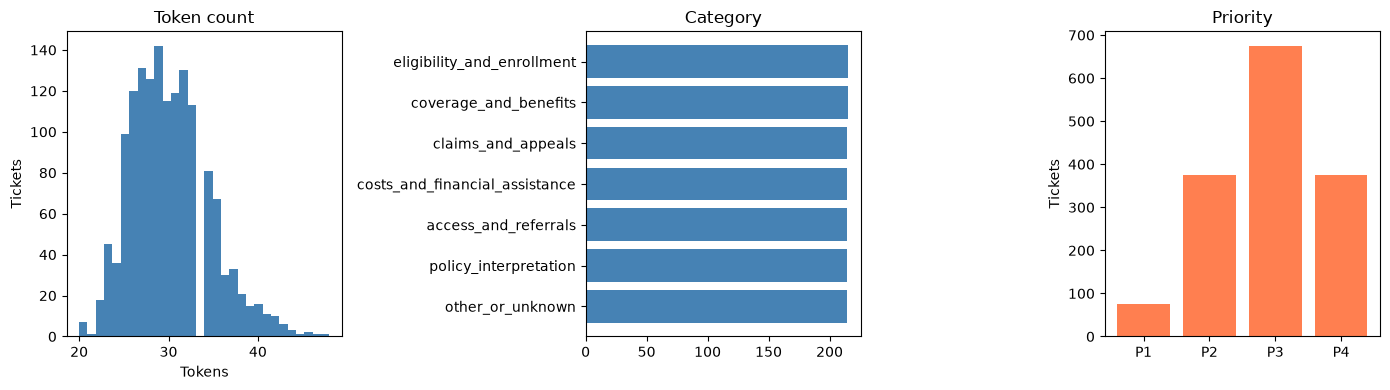

In [6]:

seq_lengths = df["tokens"].map(len)
print(f"Mean sequence length:   {seq_lengths.mean():.1f}")
print(f"Median sequence length: {seq_lengths.median():.1f}")
print(f"95th percentile:        {np.percentile(seq_lengths, 95):.0f}")
print(f"Max sequence length:    {seq_lengths.max()}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(seq_lengths, bins=30, color="steelblue")
axes[0].set_title("Token count")
axes[0].set_xlabel("Tokens")
axes[0].set_ylabel("Tickets")

cat_counts = df["category"].value_counts().reindex(CATEGORIES)
axes[1].barh(cat_counts.index, cat_counts.values, color="steelblue")
axes[1].set_title("Category")
axes[1].invert_yaxis()

pri_counts = df["priority"].value_counts().reindex(PRIORITIES)
axes[2].bar(pri_counts.index, pri_counts.values, color="coral")
axes[2].set_title("Priority")
axes[2].set_ylabel("Tickets")

fig.tight_layout()
plt.show()


Using the longest training ticket. That keeps the escalation reason, because the reason is appended at the end and the encoder trims from the end.

The Max length is 48 tokens. Every training ticket fits, including the escalation reason. A test ticket longer than every training ticket can still lose its ending, because the length is fixed from X_train before the test users are seen.


## 5. Split, vocabulary, and class weights

Users are assigned 70% / 15% / 15% to train, validation, and test. Tickets that share a `user_id` stay in one split, which is the split the dataset card asks for. The vocabulary is counted on the training users only. Any other token becomes `<OOV>`.

`get_class_weights`: Weights below 1 are raised to 1, and weights above 10 are capped, so a rare class is up weighted without being allowed to dominate.


In [7]:

rng = np.random.default_rng(SEED)
users = np.array(sorted(df["user_id"].unique()))
rng.shuffle(users)
n_train = int(len(users) * 0.70)
n_val = int(len(users) * 0.15)
train_users = set(users[:n_train])
val_users = set(users[n_train:n_train + n_val])
test_users = set(users[n_train + n_val:])
if train_users & val_users or train_users & test_users or val_users & test_users:
    raise RuntimeError("A user fell into more than one split.")
if (train_users | val_users | test_users) != set(users):
    raise RuntimeError("The user split does not cover every user.")

train_df = df[df["user_id"].isin(train_users)].copy()
val_df = df[df["user_id"].isin(val_users)].copy()
test_df = df[df["user_id"].isin(test_users)].copy()
print(f"Train tickets {len(train_df):,} from {len(train_users)} users")
print(f"Val tickets   {len(val_df):,} from {len(val_users)} users")
print(f"Test tickets  {len(test_df):,} from {len(test_users)} users")

X_train = train_df["tokens"].tolist()
X_val = val_df["tokens"].tolist()
X_test = test_df["tokens"].tolist()
y_cat_train = train_df["category_id"].to_numpy()
y_cat_val = val_df["category_id"].to_numpy()
y_cat_test = test_df["category_id"].to_numpy()
y_pri_train = train_df["priority_id"].to_numpy()
y_pri_val = val_df["priority_id"].to_numpy()
y_pri_test = test_df["priority_id"].to_numpy()

MAX_LEN = 48
VOCAB_SIZE = 10000
PAD_IDX = 0
OOV_IDX = 1
print(f"MAX_LEN = {MAX_LEN}")

token_counts = Counter(token for tokens in X_train for token in tokens)
vocab = ["<PAD>", "<OOV>"] + [word for word, _ in token_counts.most_common(VOCAB_SIZE - 2)]
word2idx = {word: index for index, word in enumerate(vocab)}
test_tokens = [token for tokens in X_test for token in tokens]
coverage = sum(token in word2idx for token in test_tokens) / max(len(test_tokens), 1)
print(f"Vocabulary size: {len(vocab):,}")
print(f"Test token coverage: {coverage:.1%}")


def encode(token_lists):
    sequences = [[word2idx.get(token, OOV_IDX) for token in tokens] for tokens in token_lists]
    return pad_sequences(
        sequences, maxlen=MAX_LEN, padding="post", truncating="post", value=PAD_IDX
    )


X_train_enc = encode(X_train)
X_val_enc = encode(X_val)
X_test_enc = encode(X_test)
print(f"Encoded train shape: {X_train_enc.shape}")


def get_class_weights(y, max_weight=10.0):
    classes = np.unique(y)
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y)
    weights = np.clip(weights, 1.0, max_weight)
    return dict(zip(classes, weights))


cat_class_weights = get_class_weights(y_cat_train)
pri_class_weights = get_class_weights(y_pri_train)
print("Category class weights:")
for index, label in enumerate(CATEGORIES):
    print(f"  {label:<32} {cat_class_weights[index]:.3f}")
print("Priority class weights:")
for index, label in enumerate(PRIORITIES):
    print(f"  {label:<32} {pri_class_weights[index]:.3f}")

cat_sample_weights = np.array([cat_class_weights[label] for label in y_cat_train])
pri_sample_weights = np.array([pri_class_weights[label] for label in y_pri_train])


Train tickets 1,050 from 350 users
Val tickets   225 from 75 users
Test tickets  225 from 75 users
MAX_LEN = 48
Vocabulary size: 229
Test token coverage: 100.0%
Encoded train shape: (1050, 48)
Category class weights:
  eligibility_and_enrollment       1.000
  coverage_and_benefits            1.000
  claims_and_appeals               1.000
  costs_and_financial_assistance   1.000
  access_and_referrals             1.087
  policy_interpretation            1.056
  other_or_unknown                 1.034
Priority class weights:
  P1                               4.688
  P2                               1.017
  P3                               1.000
  P4                               1.010



## 6. Shared BiLSTM

Both heads read one shared sequence encoding. Category has 7 outputs and priority has 4. The loss is sparse categorical cross-entropy on each head, with equal loss weights, because the service needs both decisions. Early stopping watches the sum of the two validation losses so one head does not decide the checkpoint alone.


In [10]:

BATCH_SIZE = 64
SEARCH_EPOCHS = 5
FINAL_EPOCHS = 20
DENSE_UNITS = 64
COMET_MAX_TRIALS = 12


def build_model(config):
    inputs = layers.Input(shape=(MAX_LEN,), name="input")
    hidden = layers.Embedding(len(vocab), int(config["embed_dim"]), mask_zero=True)(inputs)
    hidden = layers.SpatialDropout1D(0.2)(hidden)
    hidden = layers.Bidirectional(
        layers.LSTM(int(config["lstm_units"]), return_sequences=True)
    )(hidden)
    hidden = layers.Bidirectional(
        layers.LSTM(int(config["lstm_units"]) // 2)
    )(hidden)
    shared = layers.Dropout(float(config["dropout"]))(hidden)

    category_hidden = layers.Dense(DENSE_UNITS, activation="relu")(shared)
    category_out = layers.Dense(len(CATEGORIES), activation="softmax", name="category")(category_hidden)
    priority_hidden = layers.Dense(DENSE_UNITS, activation="relu")(shared)
    priority_out = layers.Dense(len(PRIORITIES), activation="softmax", name="priority")(priority_hidden)

    model = models.Model(
        inputs=inputs,
        outputs={"category": category_out, "priority": priority_out},
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(float(config["learning_rate"])),
        loss={
            "category": "sparse_categorical_crossentropy",
            "priority": "sparse_categorical_crossentropy",
        },
        loss_weights={"category": 1.0, "priority": 1.0},
        metrics={"category": "accuracy", "priority": "accuracy"},
    )
    return model


class EpochLogger(tf.keras.callbacks.Callback):
    def __init__(self, experiment):
        super().__init__()
        self.experiment = experiment

    def on_epoch_end(self, epoch, logs=None):
        if not logs:
            return
        clean = {key: float(value) for key, value in logs.items() if value is not None}
        self.experiment.log_metrics(clean, step=epoch)


def make_callbacks(experiment=None, patience=3):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True, mode="min"
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
        ),
    ]
    if experiment is not None:
        callbacks.append(EpochLogger(experiment))
    return callbacks


def macro_scores(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }


def predict_heads(model, features):
    predictions = model.predict(features, verbose=0)
    category_probs = predictions["category"]
    priority_probs = predictions["priority"]
    return (
        category_probs,
        priority_probs,
        category_probs.argmax(axis=1),
        priority_probs.argmax(axis=1),
    )


def log_head_metrics(experiment, split, category_scores, priority_scores):
    for name, value in category_scores.items():
        experiment.log_metric(f"{split}_category_{name}", value)
    for name, value in priority_scores.items():
        experiment.log_metric(f"{split}_priority_{name}", value)
    experiment.log_metric(
        f"{split}_mean_macro_f1",
        0.5 * (category_scores["f1"] + priority_scores["f1"]),
    )


def log_confusion(experiment, y_true, y_pred, class_names, title):
    matrix = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    experiment.log_confusion_matrix(matrix=matrix, labels=list(class_names), title=title)



## 7. Comet search

Comet proposes the next trial. Each trial trains for at most 5 epochs on the training users and is scored on the validation users. The objective logged for the optimiser is `val_mean_macro_f1`, the average of the two macro F1 scores. Category and priority metrics are logged separately, with both confusion matrices.

The width limits are tighter than the dialogue search: LSTM units from 32 to 128, embedding size from 32 to 128, dropout from 0.2 to 0.5, learning rate from 1e-4 to 1e-2 on a log scale. `COMET_MAX_TRIALS` is 12. Raise it in the previous cell if you want a longer search.


In [11]:

optimizer_config = {
    "algorithm": "bayes",
    "parameters": {
        "lstm_units": {"type": "integer", "min": 32, "max": 128},
        "embed_dim": {"type": "integer", "min": 32, "max": 128},
        "dropout": {"type": "float", "min": 0.2, "max": 0.5},
        "learning_rate": {
            "type": "float",
            "min": 1e-4,
            "max": 1e-2,
            "scalingType": "loguniform",
        },
    },
    "spec": {
        "metric": "val_mean_macro_f1",
        "objective": "maximize",
        "maxCombo": COMET_MAX_TRIALS,
    },
}

optimizer = comet_ml.Optimizer(optimizer_config, **comet_kwargs())
results = []

for experiment in optimizer.get_experiments():
    try:
        print(f"Experiment: {experiment.url}")
        config = {
            "lstm_units": int(experiment.get_parameter("lstm_units")),
            "embed_dim": int(experiment.get_parameter("embed_dim")),
            "dropout": float(experiment.get_parameter("dropout")),
            "learning_rate": float(experiment.get_parameter("learning_rate")),
        }
        experiment.set_name(
            f"lstm{config['lstm_units']}_emb{config['embed_dim']}"
            f"_drop{config['dropout']:.2f}_lr{config['learning_rate']:.6f}"
        )
        experiment.add_tag("search")
        experiment.log_parameters({
            **config,
            "batch_size": BATCH_SIZE,
            "epochs": SEARCH_EPOCHS,
            "dense_units": DENSE_UNITS,
            "max_len": MAX_LEN,
            "seed": SEED,
        })

        random.seed(SEED)
        np.random.seed(SEED)
        tf.random.set_seed(SEED)
        model = build_model(config)
        model.fit(
            X_train_enc,
            {"category": y_cat_train, "priority": y_pri_train},
            validation_data=(X_val_enc, {"category": y_cat_val, "priority": y_pri_val}),
            sample_weight={"category": cat_sample_weights, "priority": pri_sample_weights},
            epochs=SEARCH_EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=make_callbacks(experiment),
            verbose=0,
        )

        _, _, cat_pred, pri_pred = predict_heads(model, X_val_enc)
        cat_scores = macro_scores(y_cat_val, cat_pred)
        pri_scores = macro_scores(y_pri_val, pri_pred)
        log_head_metrics(experiment, "val", cat_scores, pri_scores)
        log_confusion(experiment, y_cat_val, cat_pred, CATEGORIES, "Category validation")
        log_confusion(experiment, y_pri_val, pri_pred, PRIORITIES, "Priority validation")
        mean_f1 = 0.5 * (cat_scores["f1"] + pri_scores["f1"])
        print(
            f"  lstm={config['lstm_units']} emb={config['embed_dim']} "
            f"drop={config['dropout']:.2f} lr={config['learning_rate']:.6f}"
        )
        print(f"  Category F1 {cat_scores['f1']:.4f} | Priority F1 {pri_scores['f1']:.4f} | Mean {mean_f1:.4f}")
        results.append({**config, "val_category_f1": cat_scores["f1"], "val_priority_f1": pri_scores["f1"], "val_mean_macro_f1": mean_f1,
                        "val_category_precision": cat_scores["precision"], "val_category_recall": cat_scores["recall"],
                        "val_priority_precision": pri_scores["precision"], "val_priority_recall": pri_scores["recall"],
                        "val_category_acc": cat_scores["accuracy"], "val_priority_acc": pri_scores["accuracy"]})
    finally:
        experiment.end()

results_df = pd.DataFrame(results).sort_values("val_mean_macro_f1", ascending=False)
print(results_df.to_string(index=False))
best = results_df.iloc[0]
best_config = {
    "lstm_units": int(best.lstm_units),
    "embed_dim": int(best.embed_dim),
    "dropout": float(best.dropout),
    "learning_rate": float(best.learning_rate),
}
print("\nBest config:", best_config)


Experiment: https://www.comet.com/ramy-glitch/desktriage-classifier/1f1a1f20fc9b47d2a95eb8dde628ebc4
  lstm=41 emb=89 drop=0.33 lr=0.000301
  Category F1 0.1445 | Priority F1 0.6842 | Mean 0.4144
Experiment: https://www.comet.com/ramy-glitch/desktriage-classifier/586987221b8b496c9a9f7a4fe9cffb0f
  lstm=80 emb=46 drop=0.37 lr=0.003638
  Category F1 0.9542 | Priority F1 0.9007 | Mean 0.9274
Experiment: https://www.comet.com/ramy-glitch/desktriage-classifier/8f499e2a4abe44b68c430d9322cfb02e
  lstm=56 emb=63 drop=0.47 lr=0.002155
  Category F1 0.8912 | Priority F1 0.9165 | Mean 0.9038
Experiment: https://www.comet.com/ramy-glitch/desktriage-classifier/33272fc1af264449b8293ccbe3e00830
  lstm=40 emb=108 drop=0.27 lr=0.000280
  Category F1 0.2243 | Priority F1 0.9720 | Mean 0.5981
Experiment: https://www.comet.com/ramy-glitch/desktriage-classifier/1c1b0ab77e194931ba1d80523a3f992d
  lstm=90 emb=127 drop=0.26 lr=0.003401
  Category F1 0.9569 | Priority F1 0.9792 | Mean 0.9680
Experiment: https:


## 8. Stability across seeds

The chosen widths are trained again for 5 epochs on five seeds. The seed retained for the full training run is the one with the highest validation mean macro F1. The table is a stability check. The 95% interval is a t interval around the mean of those five short runs. It is not the interval for the final 20-epoch model.


In [12]:

SEEDS = [42, 123, 2026, 7, 99]
seed_results = []
print("Stability config:", best_config)

for run_seed in SEEDS:
    print(f"\nSeed {run_seed}")
    random.seed(run_seed)
    np.random.seed(run_seed)
    tf.random.set_seed(run_seed)
    experiment = comet_ml.Experiment(**comet_kwargs())
    try:
        experiment.set_name(
            f"lstm{best_config['lstm_units']}_emb{best_config['embed_dim']}"
            f"_drop{best_config['dropout']:.2f}_lr{best_config['learning_rate']:.6f}_seed{run_seed}"
        )
        experiment.add_tag("stability")
        experiment.log_parameters({**best_config, "seed": run_seed, "epochs": SEARCH_EPOCHS})
        model = build_model(best_config)
        model.fit(
            X_train_enc,
            {"category": y_cat_train, "priority": y_pri_train},
            validation_data=(X_val_enc, {"category": y_cat_val, "priority": y_pri_val}),
            sample_weight={"category": cat_sample_weights, "priority": pri_sample_weights},
            epochs=SEARCH_EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=make_callbacks(experiment),
            verbose=0,
        )
        _, _, cat_pred, pri_pred = predict_heads(model, X_val_enc)
        cat_scores = macro_scores(y_cat_val, cat_pred)
        pri_scores = macro_scores(y_pri_val, pri_pred)
        log_head_metrics(experiment, "val", cat_scores, pri_scores)
        print(f"  {experiment.url}")
        print(f"  Category F1 {cat_scores['f1']:.4f} | Priority F1 {pri_scores['f1']:.4f}")
        seed_results.append({
            "seed": run_seed,
            "val_category_f1": cat_scores["f1"],
            "val_priority_f1": pri_scores["f1"],
            "val_mean_macro_f1": 0.5 * (cat_scores["f1"] + pri_scores["f1"]),
            "val_category_acc": cat_scores["accuracy"],
            "val_priority_acc": pri_scores["accuracy"],
        })
    finally:
        experiment.end()

seed_df = pd.DataFrame(seed_results)
print("\nPer-seed validation results:")
print(seed_df.to_string(index=False))


def mean_interval(values):
    values = np.asarray(values, dtype=float)
    mean = values.mean()
    se = values.std(ddof=1) / np.sqrt(len(values))
    low, high = stats.t.interval(0.95, len(values) - 1, loc=mean, scale=se)
    return mean, low, high


print("\n95% t intervals over the five short runs:")
for column in ["val_category_f1", "val_priority_f1", "val_mean_macro_f1"]:
    mean, low, high = mean_interval(seed_df[column])
    print(f"  {column:<24} {mean:.4f}  [{low:.4f}, {high:.4f}]")

best_seed = int(seed_df.loc[seed_df["val_mean_macro_f1"].idxmax(), "seed"])
print(f"\nSeed taken into the full training run: {best_seed}")


Stability config: {'lstm_units': 90, 'embed_dim': 127, 'dropout': 0.26455458404421384, 'learning_rate': 0.003400925315473854}

Seed 42
  https://www.comet.com/ramy-glitch/desktriage-classifier/d8057d61b1644bf69973bbda3693b995
  Category F1 0.9569 | Priority F1 0.9792

Seed 123
  https://www.comet.com/ramy-glitch/desktriage-classifier/4f2d152243e9497e9b7584eba8e354e4
  Category F1 0.9572 | Priority F1 0.9792

Seed 2026
  https://www.comet.com/ramy-glitch/desktriage-classifier/915157df9d58416fb8ed4c36a944a6dc
  Category F1 0.9533 | Priority F1 0.9750

Seed 7
  https://www.comet.com/ramy-glitch/desktriage-classifier/f2236f4b35d64ed1a1b80e5fefdf9b5c
  Category F1 0.9572 | Priority F1 0.9165

Seed 99
  https://www.comet.com/ramy-glitch/desktriage-classifier/5d38542eb98a47e0b98b97b7536ee9d7
  Category F1 0.9470 | Priority F1 0.9792

Per-seed validation results:
 seed  val_category_f1  val_priority_f1  val_mean_macro_f1  val_category_acc  val_priority_acc
   42         0.956856         0.9791


## 9. Full training run

The winning configuration and seed are trained for up to 20 epochs. Early stopping restores the checkpoint with the lowest validation loss. This run is its own Comet experiment, tagged `final`.


Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 245ms/step - category_accuracy: 0.2324 - category_loss: 1.9375 - loss: 3.0373 - priority_accuracy: 0.7200 - priority_loss: 1.0702 - val_category_accuracy: 0.4622 - val_category_loss: 1.5920 - val_loss: 1.7924 - val_priority_accuracy: 0.9289 - val_priority_loss: 0.2138 - learning_rate: 0.0034
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step - category_accuracy: 0.7352 - category_loss: 0.9078 - loss: 1.1568 - priority_accuracy: 0.9438 - priority_loss: 0.2222 - val_category_accuracy: 0.9467 - val_category_loss: 0.2220 - val_loss: 0.3106 - val_priority_accuracy: 0.9467 - val_priority_loss: 0.1069 - learning_rate: 0.0034
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 201ms/step - category_accuracy: 0.9552 - category_loss: 0.1595 - loss: 0.2990 - priority_accuracy: 0.9505 - priority_loss: 0.1340 - val_category_accuracy: 0.9511 - val_category_loss: 0.1492 - val_loss: 0.2096 - val_priority_accuracy: 0.9600 - val_priority_loss: 0.0804 - learning_rate: 0.00

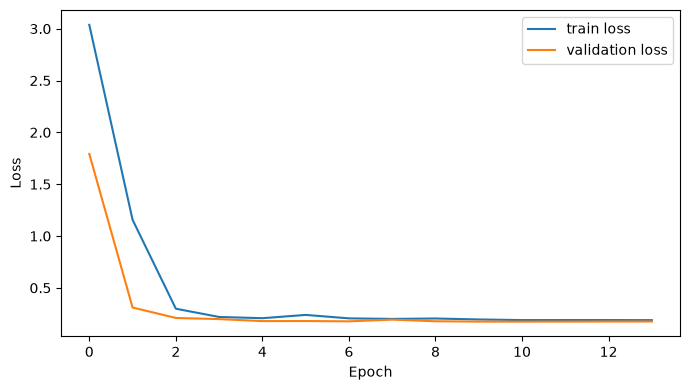

In [13]:

random.seed(best_seed)
np.random.seed(best_seed)
tf.random.set_seed(best_seed)

final_experiment = comet_ml.Experiment(**comet_kwargs())
final_experiment.set_name(f"final-bilstm-seed{best_seed}")
final_experiment.add_tag("final")
final_experiment.log_parameters({
    **best_config,
    "seed": best_seed,
    "epochs": FINAL_EPOCHS,
    "batch_size": BATCH_SIZE,
    "max_len": MAX_LEN,
    "vocab_size": len(vocab),
})

best_model = build_model(best_config)
history = best_model.fit(
    X_train_enc,
    {"category": y_cat_train, "priority": y_pri_train},
    validation_data=(X_val_enc, {"category": y_cat_val, "priority": y_pri_val}),
    sample_weight={"category": cat_sample_weights, "priority": pri_sample_weights},
    epochs=FINAL_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(final_experiment),
    verbose=1,
)
print(f"Final experiment: {final_experiment.url}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["loss"], label="train loss")
ax.plot(history.history["val_loss"], label="validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
fig.tight_layout()
plt.show()



## 10. Held-out results

The test users are scored once, after the configuration and the seed have been chosen.

P1 recall is reported on its own. Priority accuracy can look strong if a model mostly predicts P3, because P3 is 675 of 1,500 tickets.

The phrase rules are applied to the raw `query_text` of the test tickets. Those phrases were written from the priority definitions, so this score is agreement with the labels, not a second held-out discovery.

On the 225 held-out tickets the BiLSTM category head reached accuracy 0.9511 and macro F1 0.9520. The priority head reached accuracy 0.9733 and macro F1 0.9652. P1 recall was 0.8750, which is 7 of the 8 P1 tickets. The weakest category was coverage and benefits, with precision 0.70 and F1 0.83. The phrase rules on the same queries reached priority macro F1 0.9831 and P1 recall 1.0000.


BiLSTM test

Category
  acc 0.9511 | P 0.9575 | R 0.9558 | F1 0.9520
                                precision    recall  f1-score   support

    eligibility_and_enrollment       1.00      0.96      0.98        26
         coverage_and_benefits       0.70      1.00      0.83        26
            claims_and_appeals       1.00      1.00      1.00        27
costs_and_financial_assistance       1.00      0.90      0.95        31
          access_and_referrals       1.00      0.88      0.94        42
         policy_interpretation       1.00      0.97      0.99        38
              other_or_unknown       1.00      0.97      0.99        35

                      accuracy                           0.95       225
                     macro avg       0.96      0.96      0.95       225
                  weighted avg       0.97      0.95      0.95       225


Priority
  acc 0.9733 | P 0.9857 | R 0.9477 | F1 0.9652
              precision    recall  f1-score   support

          P1       1.00 

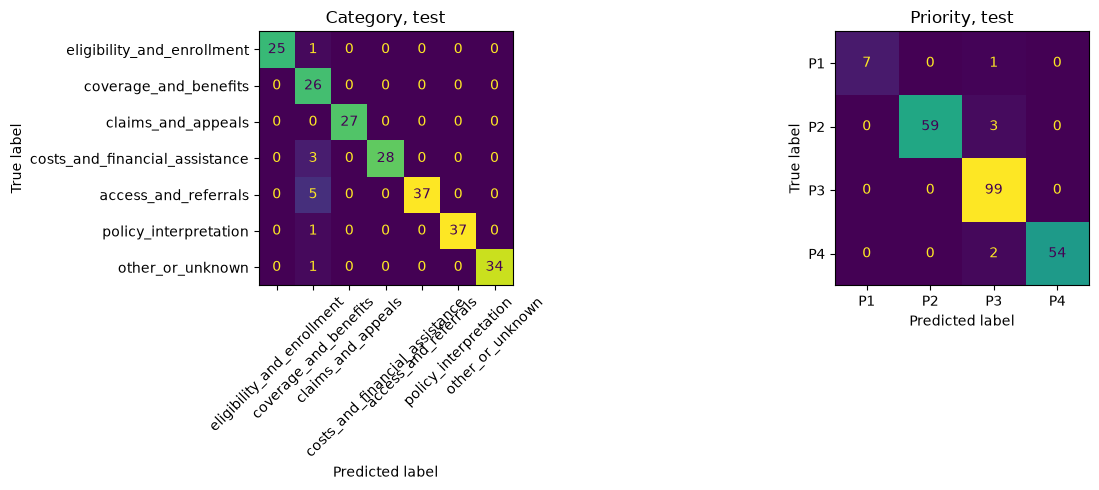

In [18]:

def p1_recall(y_true, y_pred):
    return float(recall_score(y_true, y_pred, labels=[0], average="macro", zero_division=0))


def show_task(name, y_true, y_pred, class_names):
    scores = macro_scores(y_true, y_pred)
    print(f"\n{name}")
    print(f"  acc {scores['accuracy']:.4f} | P {scores['precision']:.4f} | "
          f"R {scores['recall']:.4f} | F1 {scores['f1']:.4f}")
    print(classification_report(
        y_true, y_pred, labels=list(range(len(class_names))),
        target_names=class_names, zero_division=0,
    ))
    return scores


cat_probs, pri_probs, cat_pred, pri_pred = predict_heads(best_model, X_test_enc)

print("BiLSTM test")
bilstm_cat_test = show_task("Category", y_cat_test, cat_pred, CATEGORIES)
bilstm_pri_test = show_task("Priority", y_pri_test, pri_pred, PRIORITIES)

bilstm_p1 = p1_recall(y_pri_test, pri_pred)
print(f"\nP1 recall: {bilstm_p1:.4f}")

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "common"))
from worker.app.priority.policy import assign_priority

rule_pred = np.array([
    PRI_TO_IDX[assign_priority(query).value] for query in test_df["query_text"]
])
rule_scores = macro_scores(y_pri_test, rule_pred)
rule_p1 = p1_recall(y_pri_test, rule_pred)
print("\nPhrase-rule priority on the test queries")
print(f"  acc {rule_scores['accuracy']:.4f} | P {rule_scores['precision']:.4f} | "
      f"R {rule_scores['recall']:.4f} | F1 {rule_scores['f1']:.4f} | P1 recall {rule_p1:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_cat_test, cat_pred, labels=list(range(len(CATEGORIES)))),
    display_labels=CATEGORIES,
).plot(ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("Category, test")
ConfusionMatrixDisplay(
    confusion_matrix(y_pri_test, pri_pred, labels=list(range(len(PRIORITIES)))),
    display_labels=PRIORITIES,
).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Priority, test")
fig.tight_layout()
plt.show()

log_head_metrics(final_experiment, "test", bilstm_cat_test, bilstm_pri_test)
final_experiment.log_metric("test_p1_recall", bilstm_p1)
final_experiment.log_metric("test_rules_priority_f1", rule_scores["f1"])
final_experiment.log_metric("test_rules_p1_recall", rule_p1)
log_confusion(final_experiment, y_cat_test, cat_pred, CATEGORIES, "Category BiLSTM test")
log_confusion(final_experiment, y_pri_test, pri_pred, PRIORITIES, "Priority BiLSTM test")



## 11. Category confidence

The confidence score is the maximum probability from the category head. On the validation users, each candidate threshold records the share of tickets that would go to human review and the error rate among the tickets that would still be routed automatically.

The threshold kept is the lowest candidate at which that automatic-routing error is at most 10%. If no candidate qualifies, the candidate with the lowest automatic-routing error is kept. The test review rate is then measured at that frozen threshold. Copy the chosen value into `config/confidence.yaml` when you accept it. The labelled `requires_human_review` column is not this score.

Every candidate from 0.30 to 0.90 had validation automatic-routing error 0.000 and a review rate of 0.053. The rule therefore keeps 0.30, and that value is in `config/confidence.yaml`. At that threshold the test review rate is 0.053 and the test automatic-routing error is 0.0. The review rate did not move across the sweep, so the scores on this set sit either below 0.30 or at 0.90 and above.


In [19]:

val_cat_probs, _, _, _ = predict_heads(best_model, X_val_enc)
val_confidence = val_cat_probs.max(axis=1)
val_correct = val_cat_probs.argmax(axis=1) == y_cat_val

sweep_rows = []
for threshold in np.round(np.arange(0.30, 0.95, 0.05), 2):
    automatic = val_confidence >= threshold
    review_rate = float(1.0 - automatic.mean())
    auto_error = float((~val_correct[automatic]).mean()) if automatic.any() else None
    sweep_rows.append({
        "threshold": float(threshold),
        "review_rate": review_rate,
        "automatic_error": auto_error,
        "n_automatic": int(automatic.sum()),
    })
    auto_text = "n/a" if auto_error is None else f"{auto_error:.3f}"
    print(f"threshold {threshold:.2f}  review {review_rate:.3f}  auto error {auto_text}")

eligible = [row for row in sweep_rows if row["automatic_error"] is not None and row["automatic_error"] <= 0.10]
if eligible:
    chosen = min(eligible, key=lambda row: row["threshold"])
else:
    scored = [row for row in sweep_rows if row["automatic_error"] is not None]
    chosen = min(scored, key=lambda row: (row["automatic_error"], row["threshold"]))
CHOSEN_THRESHOLD = chosen["threshold"]
print(f"\nChosen validation threshold: {CHOSEN_THRESHOLD:.2f}")
print("Copy this value into config/confidence.yaml when you accept the trade-off.")

test_confidence = cat_probs.max(axis=1)
test_automatic = test_confidence >= CHOSEN_THRESHOLD
test_review_rate = float(1.0 - test_automatic.mean())
test_auto_error = (
    float((cat_pred[test_automatic] != y_cat_test[test_automatic]).mean())
    if test_automatic.any() else None
)
print(f"Test review rate at this threshold: {test_review_rate:.3f}")
print(f"Test automatic-routing error: {test_auto_error}")

sweep_path = MODEL_DIR / "confidence_sweep.csv"
pd.DataFrame(sweep_rows).to_csv(sweep_path, index=False)
final_experiment.log_metric("confidence_threshold", CHOSEN_THRESHOLD)
final_experiment.log_metric("val_review_rate", chosen["review_rate"])
final_experiment.log_metric("test_review_rate", test_review_rate)
final_experiment.log_table("confidence_sweep.csv", tabular_data=pd.DataFrame(sweep_rows))


threshold 0.30  review 0.053  auto error 0.000
threshold 0.35  review 0.053  auto error 0.000
threshold 0.40  review 0.053  auto error 0.000
threshold 0.45  review 0.053  auto error 0.000
threshold 0.50  review 0.053  auto error 0.000
threshold 0.55  review 0.053  auto error 0.000
threshold 0.60  review 0.053  auto error 0.000
threshold 0.65  review 0.053  auto error 0.000
threshold 0.70  review 0.053  auto error 0.000
threshold 0.75  review 0.053  auto error 0.000
threshold 0.80  review 0.053  auto error 0.000
threshold 0.85  review 0.053  auto error 0.000
threshold 0.90  review 0.053  auto error 0.000

Chosen validation threshold: 0.30
Copy this value into config/confidence.yaml when you accept the trade-off.
Test review rate at this threshold: 0.053
Test automatic-routing error: 0.0



## 12. Export

`models/category_classifier.keras` is the two-head model. `word2idx.json` is the training vocabulary and the padding length. `category_labels.json` and `priority_labels.json` are the index order of the two softmax heads. `text_prep.json` records the cleaning rules the worker has to repeat. `evaluation_summary.json` holds the held-out metrics, the P1 recall, the threshold, and the Comet URL.

The worker does not import this notebook. When `loader.py` is filled in, it should load these files with TensorFlow and apply `clean_text` the same way.

This run saved `models/category_classifier.keras` with LSTM units 90, embedding size 127, dropout 0.265, learning rate 0.003401, and seed 123. `max_len` is 48. The Comet run is https://www.comet.com/ramy-glitch/desktriage-classifier/1089d45c14034c86987eccbb0a1b799a.


In [20]:

MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "category_classifier.keras"
best_model.save(model_path)

(MODEL_DIR / "category_labels.json").write_text(
    json.dumps(CATEGORIES, indent=2) + "\n", encoding="utf-8"
)
(MODEL_DIR / "priority_labels.json").write_text(
    json.dumps(PRIORITIES, indent=2) + "\n", encoding="utf-8"
)
(MODEL_DIR / "word2idx.json").write_text(
    json.dumps({"word2idx": word2idx, "max_len": MAX_LEN, "pad_idx": PAD_IDX, "oov_idx": OOV_IDX}, indent=2) + "\n",
    encoding="utf-8",
)
(MODEL_DIR / "text_prep.json").write_text(
    json.dumps({
        "fields": ["query_text", "escalation_reason"],
        "lowercase": True,
        "contractions": CONTRACTIONS,
        "keep_tokens": ["?", "!"],
    }, indent=2) + "\n",
    encoding="utf-8",
)

summary = {
    "model": "shared-bilstm-two-head",
    "comet_project": COMET_PROJECT,
    "comet_url": final_experiment.url,
    "config": best_config,
    "seed": best_seed,
    "max_len": MAX_LEN,
    "test_category": bilstm_cat_test,
    "test_priority": bilstm_pri_test,
    "test_p1_recall": bilstm_p1,
    "test_rules_priority": rule_scores,
    "test_rules_p1_recall": rule_p1,
    "confidence_threshold": CHOSEN_THRESHOLD,
    "val_review_rate": chosen["review_rate"],
    "val_automatic_error": chosen["automatic_error"],
    "test_review_rate": test_review_rate,
    "test_automatic_error": test_auto_error,
    "seed_validation": seed_df.to_dict(orient="records"),
    "dataset": "synthetic desktriage tickets",
}
summary_path = MODEL_DIR / "evaluation_summary.json"
summary_path.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")

loaded = tf.keras.models.load_model(model_path)
loaded_cat, loaded_pri, _, _ = predict_heads(loaded, X_test_enc[:8])
if not np.allclose(loaded_cat, cat_probs[:8], atol=1e-5):
    raise RuntimeError("The reloaded category head does not match the model just trained.")
if not np.allclose(loaded_pri, pri_probs[:8], atol=1e-5):
    raise RuntimeError("The reloaded priority head does not match the model just trained.")

final_experiment.log_asset(str(summary_path), file_name="evaluation_summary.json")
final_experiment.log_model("desktriage-bilstm", str(model_path))
final_experiment.end()
print(f"Saved {model_path}")
print(f"Comet run: {summary['comet_url']}")


Saved c:\Users\Ramy\my projects\Desktriage\models\category_classifier.keras
Comet run: https://www.comet.com/ramy-glitch/desktriage-classifier/1089d45c14034c86987eccbb0a1b799a



## References

Caruana, R. (1997) Multitask learning. *Machine Learning*, 28(1), pp. 41–75. Available at: https://www.cs.cornell.edu/~caruana/mlj97.pdf

Cunha, W., Rocha, L. and Gonçalves, M.A. (2025) A thorough benchmark of automatic text classification: from traditional approaches to large language models. arXiv:2504.01930. Available at: https://arxiv.org/abs/2504.01930

Evaluating text classification: a benchmark study (2024) *Expert Systems with Applications*, 254, 124302. Available at: https://doi.org/10.1016/j.eswa.2024.124302

Graves, A. and Schmidhuber, J. (2005) Framewise phoneme classification with bidirectional LSTM networks. *Proceedings of the 2005 IEEE International Joint Conference on Neural Networks*. Available at: https://www.cs.toronto.edu/~graves/ijcnn_2005.pdf

Li, L., Jamieson, K., DeSalvo, G., Rostamizadeh, A. and Talwalkar, A. (2018) Hyperband: a novel bandit-based approach to hyperparameter optimization. *Journal of Machine Learning Research*, 18(185), pp. 1–52. Available at: https://www.jmlr.org/papers/volume18/16-558/16-558.pdf

Pes, B. and Lai, G. (2021) Cost-sensitive learning strategies for high-dimensional and imbalanced data. *PeerJ Computer Science*, 7, e832. Available at: https://peerj.com/articles/cs-832/

Roszczyk, R., Tecza, P., Stodolski, M. and Siwek, K. (2026) Natural language processing models for robust document categorization. arXiv:2602.20336. Available at: https://arxiv.org/abs/2602.20336

Zangari, A., Marcuzzo, M., Schiavinato, M., Gasparetto, A. and Albarelli, A. (2023) Ticket automation: an insight into current research with applications to multi-level classification scenarios. *Expert Systems with Applications*, 225, 119984. Available at: https://www.sciencedirect.com/science/article/pii/S0957417423004864
